# CodeGraph-RAG / PathPack
### Исследовательский ноутбук, этап 1 · 1–2 ноября 2026

**Цель:** показать, как из Python-репозитория получить граф кода и использовать его для анализа связей. Это подготовка к исследованию выбора контекста для локальных ИИ-агентов.

> Важно: **PathPack ещё не реализован**, реальный SWE-bench Verified ещё не обработан, а эффективность метода пока не измерена. Все визуализации ниже построены по реальному коду в комплекте, но не доказывают улучшение исправления ошибок.

## 1. Наша исследовательская гипотеза

Обычный поиск по тексту или эмбеддингам может пропускать зависимости, которые нужны для исправления бага. Предполагаем, что **подбор связанных фрагментов кода с учётом графа и лимита токенов** повысит качество локализации ошибки.

План эксперимента: сравнить BM25, эмбеддинги, простое расширение графа и PathPack на одинаковом наборе задач и бюджете токенов. Эталонные исправления из `patch` будут доступны только оценщику.

### Схема

`Issue → поиск точек входа → AST-граф → PathPack (будет реализован позже) → контекст → локальная LLM → patch`

In [1]:
from pathlib import Path
import sys

# Работаем и из корня проекта, и при открытии ноутбука из папки notebooks.
wd = Path.cwd().resolve()
candidates = [wd, *wd.parents, wd / "CodeGraph-RAG-Research-Kit"]
ROOT = next((p for p in candidates if (p / "src/codegraph_rag/parser.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Открой ноутбук из папки проекта или её подпапки")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from codegraph_rag.parser import scan_repository
from codegraph_rag.visualize import draw_graph
import networkx as nx
import matplotlib.pyplot as plt

print("Корень проекта:", ROOT)

Корень проекта: /mnt/data/CodeGraph-RAG-Research-Kit


## 2. Посмотрим на исходники небольшого проекта

В `examples/sample_repo/` есть две функции: `login()` и `get_user()`. Функция `login()` вызывает `get_user()`, хотя они находятся в разных файлах. Это простая иллюстрация зависимости, которую должен учитывать поиск контекста.

In [2]:
for file in [ROOT / "examples/sample_repo/service.py", ROOT / "examples/sample_repo/storage.py"]:
    print("\n===", file.name, "===")
    print(file.read_text(encoding="utf-8"))


=== service.py ===
from .storage import get_user


def login(user_id: int) -> str:
    user = get_user(user_id)
    return user["name"]


=== storage.py ===
USERS = {1: {"name": "Ada"}}


def get_user(user_id: int) -> dict:
    return USERS[user_id]



## 3. AST-парсер строит граф

Мы не импортируем и не исполняем исследуемый проект: читаем исходники, используем `ast.parse()`, записываем определения и разрешённые статические связи. У каждой вершины есть файл, полное имя и номера строк.

In [3]:
graph = scan_repository(ROOT / "examples")
stats = graph.stats()
print("Вершин:", stats["nodes"])
print("Рёбер:", stats["edges"])
print("Типы вершин:", stats["symbols"])
print("Типы связей:", stats["relations"])
print("Ошибки разбора:", stats["parse_errors"])
assert stats["nodes"] == 5 and stats["edges"] == 7

Вершин: 5
Рёбер: 7
Типы вершин: {'function': 2, 'module': 3}
Типы связей: {'calls': 1, 'defines': 2, 'imports': 4}
Ошибки разбора: {}


## 4. Визуализация №1: импорты и вызовы

- Тёмные вершины: модули.
- Бирюзовые: функции.
- Фиолетовые пунктирные стрелки: импорты.
- Серые: определения.
- Бирюзовые стрелки: вызовы функций.

Направление стрелки показывает, кто зависит от чего: например, `login()` **вызывает** `get_user()`.

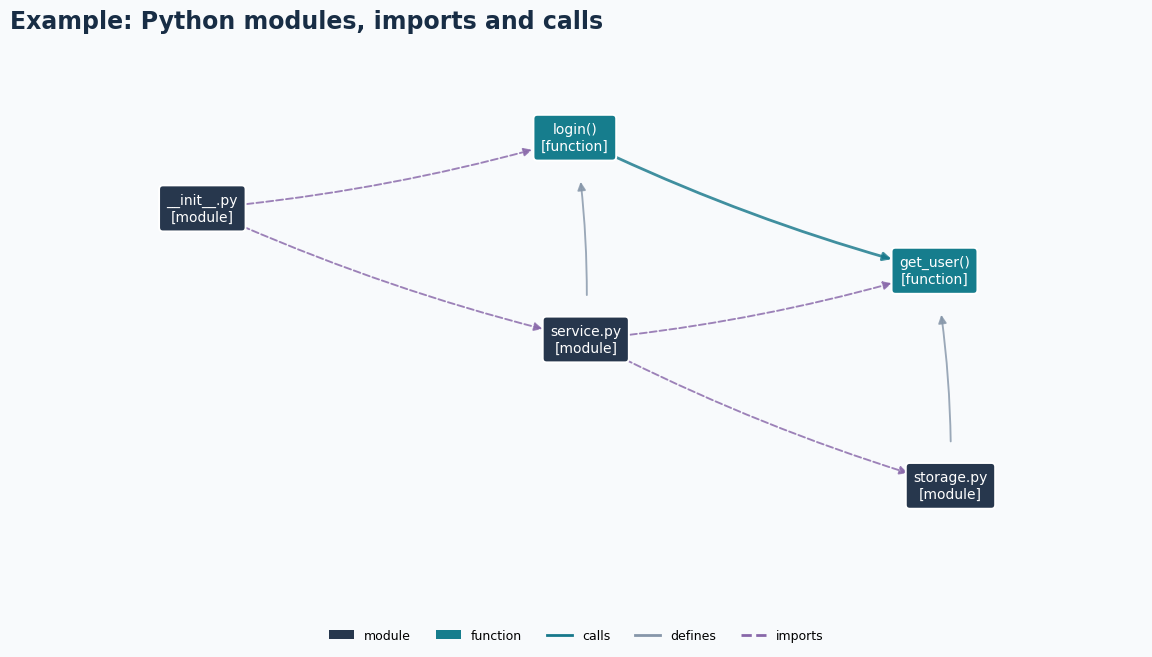

In [4]:
fig = draw_graph(graph.to_dict(), title="Example: Python modules, imports and calls", figsize=(11.8, 6.8))
plt.show()

### Пример данных графа

Вот часть рёбер, которые действительно выделил парсер. `defines` и `imports` не означают вызов функции. Разделять типы связей важно для будущего PathPack.

In [5]:
for edge in sorted(graph.edges, key=lambda e: (e.kind,e.source,e.target)):
    src = edge.source.split("::")[-1]
    dst = edge.target.split("::")[-1]
    print(f"{edge.kind:8} | {src:14} -> {dst}")

calls    | login          -> get_user
defines  | __module__     -> login
defines  | __module__     -> get_user
imports  | __module__     -> __module__
imports  | __module__     -> login
imports  | __module__     -> __module__
imports  | __module__     -> get_user


## 5. Небольшой кусок AST-кода

Отдельный пример демонстрирует, как Python AST представляет вызов функции. В полноценном парсере эти вызовы связываются с определениями через таблицы символов и импорты.

In [6]:
import ast
source = (ROOT / "examples/sample_repo/service.py").read_text(encoding="utf-8")
tree = ast.parse(source)
for node in ast.walk(tree):
    if isinstance(node, ast.Call):
        print("Строка", node.lineno, "вызов:", ast.unparse(node.func))

Строка 5 вызов: get_user


## 6. Визуализация №2: граф реального проекта

Теперь сканируем **исходники самого CodeGraph-RAG**. Рядом с `scan_repository()` находятся функции, которые он вызывает, и вызывающие его функции или тесты. Для читаемости показываем только связи типа `calls` на расстоянии одного шага.

Статистика собственного проекта: {'nodes': 63, 'edges': 110, 'symbols': {'class': 9, 'function': 17, 'method': 24, 'module': 13}, 'relations': {'calls': 37, 'defines': 50, 'imports': 23}, 'parse_errors': {}}


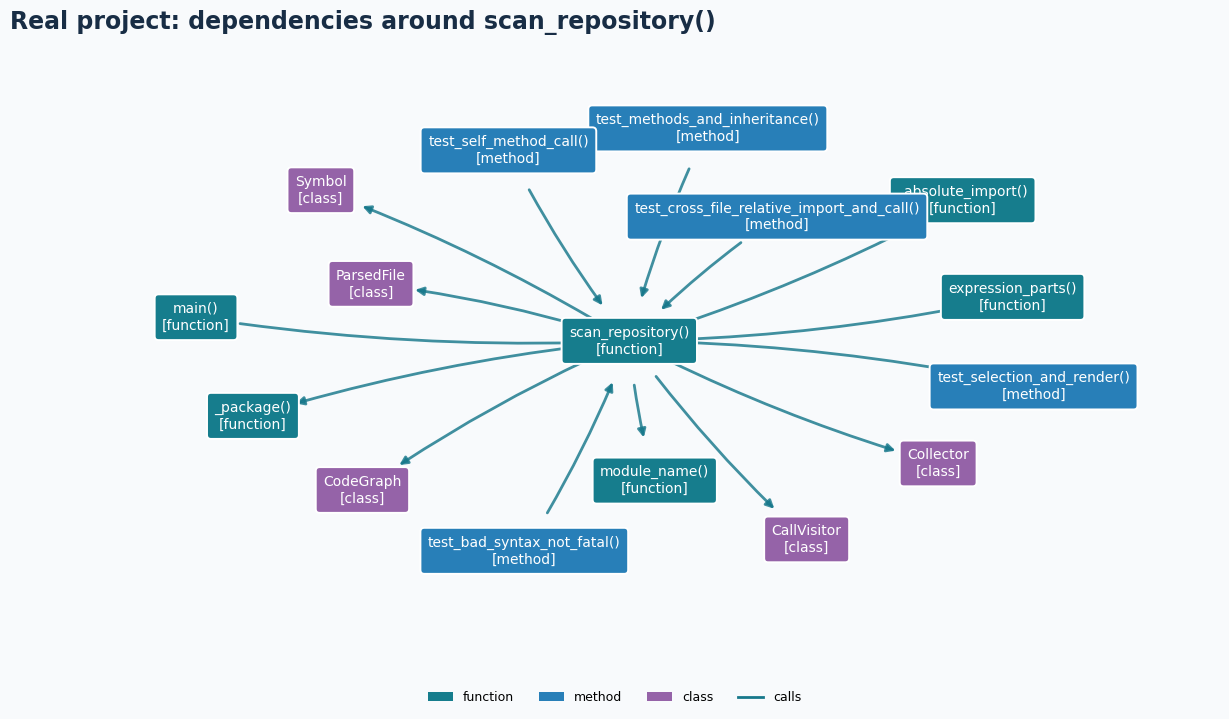

In [7]:
project_graph = scan_repository(ROOT)
print("Статистика собственного проекта:", project_graph.stats())
fig = draw_graph(project_graph.to_dict(),
    title="Real project: dependencies around scan_repository()",
    focus="parser.py::scan_repository", hops=1,
    edge_kinds={"calls"}, max_nodes=19,
    figsize=(12.6,7.5))
plt.show()

## 7. Демонстрация пути между функциями

Для PathPack нам понадобятся пути по графу. Пока просто найдём кратчайший путь **по связям вызова**, без ранжирования и ограничения токенов.

In [8]:
calls = nx.DiGraph()
calls.add_edges_from((e.source,e.target) for e in graph.edges if e.kind == "calls")
start = "sample_repo/service.py::login"
finish = "sample_repo/storage.py::get_user"
path = nx.shortest_path(calls, start, finish)
print(" → ".join(p.split("::")[-1] for p in path))
print("Длина пути (рёбер):", len(path)-1)

login → get_user
Длина пути (рёбер): 1


## 8. Что делаем дальше (2 ноября)

1. Получить 80 задач SWE-bench Verified с фиксированным `seed=42` (20 dev / 60 test).
2. Скачать Python-репозитории на версии `base_commit` (не после исправления).
3. Построить реальные графы и сохранить статистику: количество узлов, рёбер, ошибки разбора, время.
4. Отдельно хранить `gold_labels.jsonl`. **Запрещено передавать метки из patch в поисковый алгоритм.**
5. Просмотреть 5 неточных или потерянных статических зависимостей.

Команды для терминала (не запускаются внутри ноутбука):

```bash
pip install -e '.[benchmark,viz]'
codegraph prepare --out output/benchmark --limit 80 --dev-count 20 --seed 42
codegraph scan /path/to/repository_at_base_commit --out output/repo-graph.json
codegraph visualize output/repo-graph.json --out visualizations/real-repo.png --max-nodes 35
```

**Ограничение:** команда `prepare` готовит метаданные, но не клонирует репозитории, не применяет патчи и не запускает тесты SWE-bench. Интернет нужен только для получения датасета/репозиториев, но не для выполнения этого ноутбука.

### Что будет считаться научным результатом

Не красивые графы, а проверяемое улучшение относительно базовых методов при **одинаковом бюджете токенов**. Возможен и отрицательный результат: его нужно честно описать.